In [1]:

import os
import pandas as pd

data_path = "/content"

files = [f for f in os.listdir(data_path) if f.endswith(".csv")]

print("Total CSV files found:", len(files))
print("\nAvailable datasets:")

for file in sorted(files):
    print(file)


Total CSV files found: 9

Available datasets:
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [2]:

orders = pd.read_csv("/content/olist_orders_dataset.csv")

print("Dataset shape:", orders.shape)
print("\nFirst 5 rows:")
display(orders.head())

print("\nColumn names:")
print(orders.columns.tolist())


Dataset shape: (99441, 8)

First 5 rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Column names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


In [3]:

print("Dataset information:")
orders.info()

print("\nMissing values:")
display(orders.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate order IDs:", orders["order_id"].duplicated().sum())

print("\nOrder status distribution:")
display(orders["order_status"].value_counts().to_frame("Order Count"))


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing values:


,Missing Values
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0



Duplicate order IDs: 0

Order status distribution:


,Order Count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [4]:

import pandas as pd
import numpy as np
import os

# Load the original dataset
orders = pd.read_csv("/content/olist_orders_dataset.csv")

# Preserve the original data; work on a copy
orders_clean = orders.copy()

# Convert date columns to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col], errors="coerce"
    )

# 1. Data-quality audit
audit = pd.DataFrame({
    "Column": orders_clean.columns,
    "Data Type": orders_clean.dtypes.astype(str).values,
    "Missing Values": orders_clean.isnull().sum().values,
    "Missing Percentage": (
        orders_clean.isnull().mean().values * 100
    ).round(2)
})

print("DATA QUALITY AUDIT")
display(audit)

# 2. Check duplicate order IDs
print("Duplicate order IDs:",
      orders_clean["order_id"].duplicated().sum())

# 3. Check invalid date sequences
invalid_approval = (
    orders_clean["order_approved_at"].notna()
    & (orders_clean["order_approved_at"]
       < orders_clean["order_purchase_timestamp"])
)

invalid_carrier = (
    orders_clean["order_delivered_carrier_date"].notna()
    & (orders_clean["order_delivered_carrier_date"]
       < orders_clean["order_purchase_timestamp"])
)

invalid_delivery = (
    orders_clean["order_delivered_customer_date"].notna()
    & (orders_clean["order_delivered_customer_date"]
       < orders_clean["order_purchase_timestamp"])
)

print("\nINVALID DATE SEQUENCES")
print("Approval before purchase:", invalid_approval.sum())
print("Carrier date before purchase:", invalid_carrier.sum())
print("Customer delivery before purchase:", invalid_delivery.sum())

# 4. Calculate delivery duration for valid delivered orders
delivered = orders_clean[
    (orders_clean["order_status"] == "delivered")
    & orders_clean["order_purchase_timestamp"].notna()
    & orders_clean["order_delivered_customer_date"].notna()
].copy()

delivered["delivery_duration_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print("\nDELIVERY DURATION CHECK")
print("Delivered orders with usable dates:", len(delivered))
print("Negative delivery durations:",
      (delivered["delivery_duration_days"] < 0).sum())

print("\nDelivery duration summary:")
display(delivered["delivery_duration_days"].describe())

# 5. Save interim data without overwriting raw data
os.makedirs("/content/data/interim", exist_ok=True)

orders_clean.to_csv(
    "/content/data/interim/orders_interim.csv",
    index=False
)

print("\nSaved: /content/data/interim/orders_interim.csv")


DATA QUALITY AUDIT


,Column,Data Type,Missing Values,Missing Percentage
0,order_id,object,0,0.00
1,customer_id,object,0,0.00
2,order_status,object,0,0.00
3,order_purchase_timestamp,datetime64[ns],0,0.00
4,order_approved_at,datetime64[ns],160,0.16
5,order_delivered_carrier_date,datetime64[ns],1783,1.79
6,order_delivered_customer_date,datetime64[ns],2965,2.98
7,order_estimated_delivery_date,datetime64[ns],0,0.00


Duplicate order IDs: 0

INVALID DATE SEQUENCES
Approval before purchase: 0
Carrier date before purchase: 166
Customer delivery before purchase: 0

DELIVERY DURATION CHECK
Delivered orders with usable dates: 96470
Negative delivery durations: 0

Delivery duration summary:


,delivery_duration_days
count,96470.000000
mean,12.558217
std,9.546156
min,0.533414
25%,6.766204
50%,10.217477
75%,15.720182
max,209.628611



Saved: /content/data/interim/orders_interim.csv


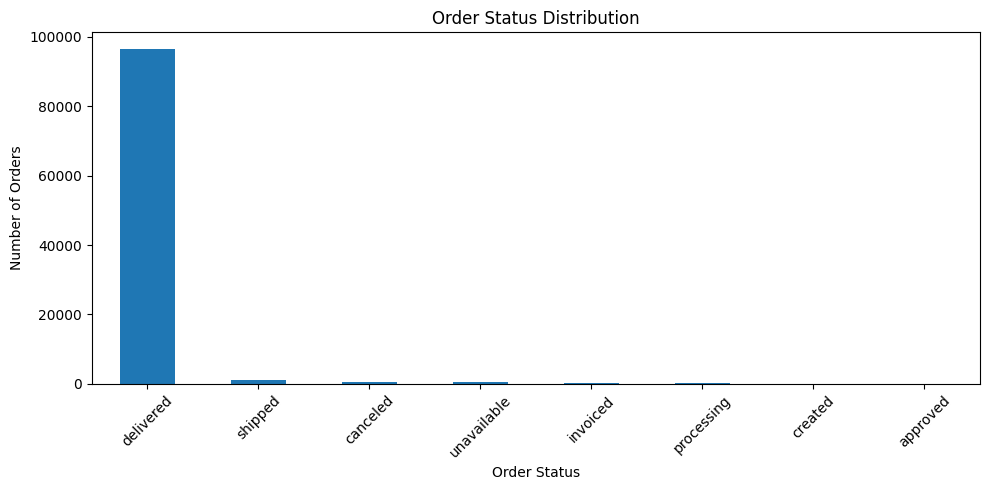

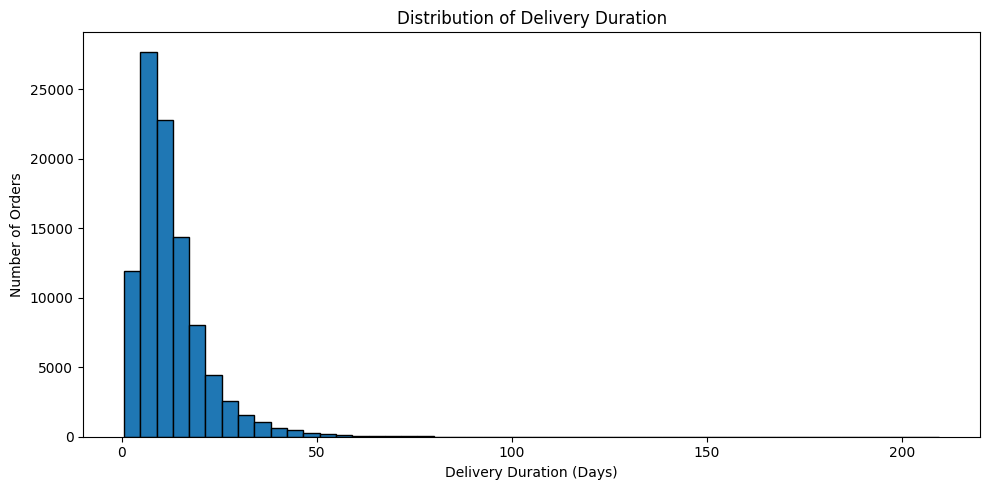

EDA charts saved successfully.


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the interim dataset
orders = pd.read_csv(
    "/content/data/interim/orders_interim.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "order_delivered_carrier_date",
        "order_approved_at"
    ]
)

os.makedirs("/content/reports/figures", exist_ok=True)

# Chart 1: Order status distribution
status_counts = orders["order_status"].value_counts()

plt.figure(figsize=(10, 5))
status_counts.plot(kind="bar")
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "/content/reports/figures/order_status_distribution.png",
    dpi=300
)
plt.show()

# Chart 2: Delivery duration distribution
delivered = orders[
    (orders["order_status"] == "delivered")
    & orders["order_purchase_timestamp"].notna()
    & orders["order_delivered_customer_date"].notna()
].copy()

delivered["delivery_duration_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

plt.figure(figsize=(10, 5))
plt.hist(
    delivered["delivery_duration_days"],
    bins=50,
    edgecolor="black"
)
plt.title("Distribution of Delivery Duration")
plt.xlabel("Delivery Duration (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.savefig(
    "/content/reports/figures/delivery_duration_distribution.png",
    dpi=300
)
plt.show()

print("EDA charts saved successfully.")


DELIVERY PERFORMANCE KPIs
--------------------------
Eligible delivered orders: 96470
On-time or early orders: 89936
Late orders: 6534
On-time delivery rate: 93.23%
Late delivery rate: 6.77%
Average delay (signed): -11.88 days

Delivery outcome counts:


,Orders
delivery_outcome,
Early,88644
Late,6534
On time,1292


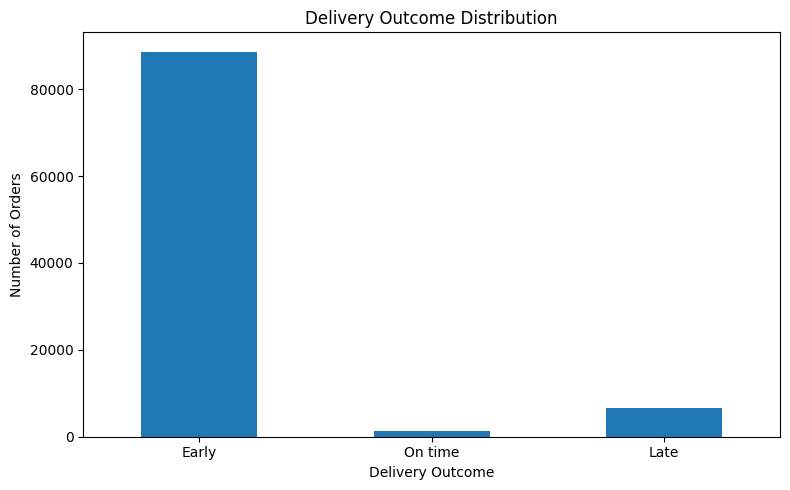

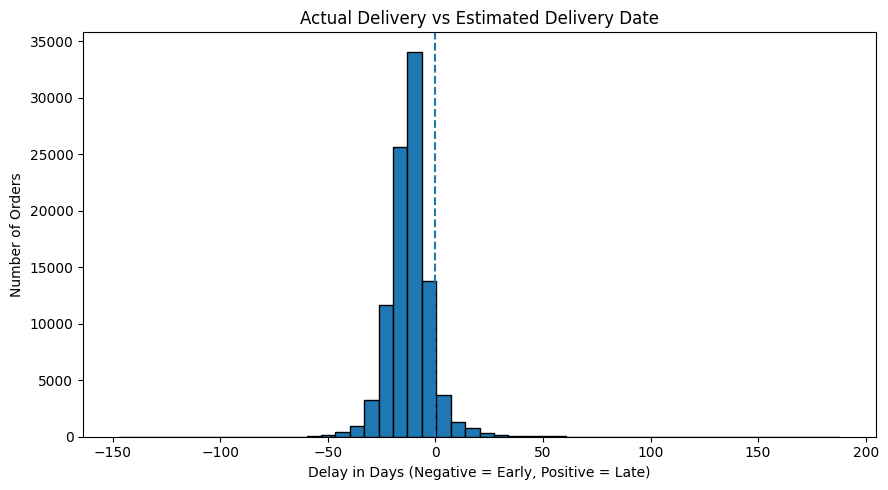

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the interim dataset
orders = pd.read_csv(
    "/content/data/interim/orders_interim.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

# Use delivered orders with both actual and estimated dates
delivery = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

# Positive delay means delivery was late
delivery["delay_days"] = (
    delivery["order_delivered_customer_date"].dt.normalize()
    - delivery["order_estimated_delivery_date"].dt.normalize()
).dt.total_seconds() / 86400

# Classify delivery outcome
delivery["delivery_outcome"] = delivery["delay_days"].apply(
    lambda x: "Late" if x > 0
    else ("On time" if x == 0 else "Early")
)

# Calculate KPIs
total_eligible = len(delivery)
on_time = (delivery["delay_days"] <= 0).sum()
late = (delivery["delay_days"] > 0).sum()

on_time_rate = (
    on_time / total_eligible * 100
    if total_eligible else 0
)

late_rate = (
    late / total_eligible * 100
    if total_eligible else 0
)

average_delay = delivery["delay_days"].mean()

print("DELIVERY PERFORMANCE KPIs")
print("--------------------------")
print("Eligible delivered orders:", total_eligible)
print("On-time or early orders:", on_time)
print("Late orders:", late)
print(f"On-time delivery rate: {on_time_rate:.2f}%")
print(f"Late delivery rate: {late_rate:.2f}%")
print(f"Average delay (signed): {average_delay:.2f} days")

print("\nDelivery outcome counts:")
display(delivery["delivery_outcome"].value_counts().to_frame("Orders"))

# Plot delivery outcomes
os.makedirs("/content/reports/figures", exist_ok=True)

outcome_counts = delivery["delivery_outcome"].value_counts().reindex(
    ["Early", "On time", "Late"], fill_value=0
)

plt.figure(figsize=(8, 5))
outcome_counts.plot(kind="bar")
plt.title("Delivery Outcome Distribution")
plt.xlabel("Delivery Outcome")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "/content/reports/figures/delivery_outcomes.png",
    dpi=300
)
plt.show()

# Plot signed delivery delay
plt.figure(figsize=(9, 5))
plt.hist(delivery["delay_days"], bins=50, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.title("Actual Delivery vs Estimated Delivery Date")
plt.xlabel("Delay in Days (Negative = Early, Positive = Late)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.savefig(
    "/content/reports/figures/delivery_delay_distribution.png",
    dpi=300
)
plt.show()


In [7]:

import os
import pandas as pd

base = "/content"
os.makedirs(f"{base}/reports", exist_ok=True)
os.makedirs(f"{base}/data/interim", exist_ok=True)

orders = pd.read_csv(f"{base}/data/interim/orders_interim.csv")

# Data dictionary for the orders table
data_dictionary = pd.DataFrame([
    ["order_id", "Unique order identifier", "Identifier"],
    ["customer_id", "Customer identifier associated with the order", "Identifier"],
    ["order_status", "Current recorded order status", "Categorical"],
    ["order_purchase_timestamp", "Date and time the order was placed", "Datetime"],
    ["order_approved_at", "Date and time the order was approved", "Datetime"],
    ["order_delivered_carrier_date", "Date and time the order was handed to the carrier", "Datetime"],
    ["order_delivered_customer_date", "Date and time the customer received the order", "Datetime"],
    ["order_estimated_delivery_date", "Estimated delivery date", "Datetime"]
], columns=["Column", "Description", "Data Type"])

data_dictionary.to_csv(
    f"{base}/reports/data_dictionary.csv", index=False
)

# Save the data-quality audit
audit = pd.DataFrame({
    "column": orders.columns,
    "data_type": orders.dtypes.astype(str).values,
    "missing_values": orders.isnull().sum().values,
    "missing_percentage": (
        orders.isnull().mean().values * 100
    ).round(2)
})

audit.to_csv(
    f"{base}/reports/data_quality_audit.csv", index=False
)

# Save the status distribution
orders["order_status"].value_counts().rename_axis(
    "order_status"
).reset_index(name="order_count").to_csv(
    f"{base}/reports/order_status_summary.csv", index=False
)

print("Week 1 documentation files created:")
print("- reports/data_dictionary.csv")
print("- reports/data_quality_audit.csv")
print("- reports/order_status_summary.csv")


Week 1 documentation files created:
- reports/data_dictionary.csv
- reports/data_quality_audit.csv
- reports/order_status_summary.csv


In [8]:

import os
import pandas as pd

# Create the reports folder
os.makedirs("/content/reports", exist_ok=True)

# Document the data-cleaning rules
cleaning_rules = pd.DataFrame([
    {
        "Issue": "Missing approval timestamps",
        "Finding": "160 missing values",
        "Cleaning rule": "Keep the records; exclude missing timestamps only from calculations requiring approval time."
    },
    {
        "Issue": "Missing carrier delivery timestamps",
        "Finding": "Missing values present",
        "Cleaning rule": "Keep the records; exclude missing timestamps from carrier-related duration calculations."
    },
    {
        "Issue": "Missing customer delivery timestamps",
        "Finding": "Missing values present",
        "Cleaning rule": "Keep the records; exclude from actual delivery duration and delivery outcome KPIs."
    },
    {
        "Issue": "Duplicate order IDs",
        "Finding": "0 duplicates found",
        "Cleaning rule": "Retain all records; repeat this check after any joins."
    },
    {
        "Issue": "Carrier date before purchase date",
        "Finding": "166 records flagged",
        "Cleaning rule": "Flag for investigation; do not use these timestamps for affected duration calculations until validated."
    },
    {
        "Issue": "Negative customer delivery duration",
        "Finding": "0 found among records with usable dates",
        "Cleaning rule": "Retain valid records and repeat the check after transformations."
    },
    {
        "Issue": "Unusually long delivery duration",
        "Finding": "Maximum approximately 209.63 days",
        "Cleaning rule": "Flag for review; do not remove automatically without evidence."
    },
    {
        "Issue": "Order status",
        "Finding": "Multiple statuses present",
        "Cleaning rule": "Preserve original statuses; define eligible orders separately for each KPI."
    },
    {
        "Issue": "Date fields",
        "Finding": "Parsed using pandas datetime conversion",
        "Cleaning rule": "Use consistent datetime types and document any values converted to missing."
    }
])

# Save the rules
cleaning_rules.to_csv(
    "/content/reports/data_cleaning_rules.csv",
    index=False
)

print("Cleaning rules saved successfully!")
display(cleaning_rules)


Cleaning rules saved successfully!


,Issue,Finding,Cleaning rule
0,Missing approval timestamps,160 missing values,Keep the records; exclude missing timestamps o...
1,Missing carrier delivery timestamps,Missing values present,Keep the records; exclude missing timestamps f...
2,Missing customer delivery timestamps,Missing values present,Keep the records; exclude from actual delivery...
3,Duplicate order IDs,0 duplicates found,Retain all records; repeat this check after an...
4,Carrier date before purchase date,166 records flagged,Flag for investigation; do not use these times...
5,Negative customer delivery duration,0 found among records with usable dates,Retain valid records and repeat the check afte...
6,Unusually long delivery duration,Maximum approximately 209.63 days,Flag for review; do not remove automatically w...
7,Order status,Multiple statuses present,Preserve original statuses; define eligible or...
8,Date fields,Parsed using pandas datetime conversion,Use consistent datetime types and document any...


In [9]:

import os
import zipfile

zip_path = "/content/week1_project_files.zip"

folders_to_include = [
    "/content/data/interim",
    "/content/reports"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder in folders_to_include:
        if os.path.exists(folder):
            for root, dirs, files in os.walk(folder):
                for file in files:
                    file_path = os.path.join(root, file)
                    arcname = os.path.relpath(file_path, "/content")
                    zipf.write(file_path, arcname)

print("Week 1 project files packaged successfully!")
print("ZIP file:", zip_path)


Week 1 project files packaged successfully!
ZIP file: /content/week1_project_files.zip


In [10]:

from google.colab import files

files.download("/content/week1_project_files.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>